In [17]:
# Import libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Load dataset
df = pd.read_csv("Employers_data.csv")

In [18]:
# Display first rows
df.head()

,Employee_ID,Name,Age,Gender,Department,Job_Title,Experience_Years,Education_Level,Location,Salary
0,1,Merle Ingram,24,Female,Engineering,Engineer,1,Master,Austin,90000
1,2,John Mayes,56,Male,Sales,Executive,33,Master,Seattle,195000
2,3,Carlos Wille,21,Male,Engineering,Intern,1,Bachelor,New York,35000
3,4,Michael Bryant,30,Male,Finance,Analyst,9,Bachelor,New York,75000
4,5,Paula Douglas,25,Female,HR,Analyst,2,Master,Seattle,70000


In [19]:
# Define target
y = df["Salary"]

# Select input features
X = df.drop(
    columns=["Salary", "Employee_ID", "Name", "Gender"]
)

print("Features:", X.columns.tolist())
print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['Age', 'Department', 'Job_Title', 'Experience_Years', 'Education_Level', 'Location']
X shape: (10000, 6)
y shape: (10000,)


In [30]:
# Split features (X) and target (y) into training and testing sets
# test_size=0.2: Use 20% for testing and 80% for training
# random_state=42: Ensure the same random split across runs

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Check the number of rows and features in each set
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (8000, 6)
Testing: (2000, 6)


In [ ]:
# Identify numerical features for scaling
numerical_features = ["Age", "Experience_Years"]

# Identify categorical features for one-hot encoding
categorical_features = [
    "Department",
    "Job_Title",
    "Education_Level",
    "Location"
]

In [ ]:
# Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Define preprocessing for numerical and categorical features
preprocessor = ColumnTransformer([

    # Standardize numerical features using mean and standard deviation
    ("num", StandardScaler(), numerical_features),

    # Convert categorical features into binary columns
    # Ignore unseen categories during prediction
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)

])

In [ ]:
# Import regression models
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import make_scorer, root_mean_squared_error

# Divide training data into 5 folds for cross-validation
cv = KFold(
    n_splits=5,        # Use 5 folds
    shuffle=True,      # Shuffle data before creating folds
    random_state=42    # Keep the same folds across runs
)

# Define models
models = {
    
    # Predict the mean salary as a simple baseline
    "Baseline": DummyRegressor(strategy="mean"),
    
    "Linear Regression": LinearRegression(),
    
    "Decision Tree": DecisionTreeRegressor(
        max_depth=5, random_state=42
    ),
    
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

# Compare models using cross-validation
results = []

# Iterate through each regression model
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            # Negative error scores are used because higher scores are preferred
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        
        # Use all available CPU workers for parallel processing
        n_jobs=-1
    )

    # Store the average evaluation metrics for each model
    results.append({
        "Model": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean()
    })

# Convert results into a DataFrame and rank models by lowest MAE
results_df = pd.DataFrame(results)

display(
    results_df.sort_values("MAE").round(3)
)

,Model,MAE,RMSE,R2
1,Linear Regression,3429.225,4289.893,0.991
4,Gradient Boosting,3479.626,4352.895,0.991
2,Decision Tree,3757.060,4663.828,0.990
3,Random Forest,3860.714,4854.780,0.989
0,Baseline,39513.086,46101.441,-0.000


In [31]:
# Import the Linear Regression model
from sklearn.linear_model import LinearRegression

# Create a pipeline that combines preprocessing and model training
linear_pipeline = Pipeline([

    # Apply scaling and one-hot encoding
    ("preprocessing", preprocessor),

    # Use Linear Regression to predict salaries
    ("model", LinearRegression())
])

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

# Train the final Linear Regression pipeline on all 8,000 training records
linear_pipeline.fit(X_train, y_train)

# Predict salaries for the 2,000 unseen test records
y_pred = linear_pipeline.predict(X_test)

# Evaluate final performance
print("Test MAE:", mean_absolute_error(y_test, y_pred))
print("Test RMSE:", root_mean_squared_error(y_test, y_pred))
print("Test R2:", r2_score(y_test, y_pred))

Test MAE: 3337.970927508934
Test RMSE: 4168.123888246173
Test R2: 0.9917570953979876


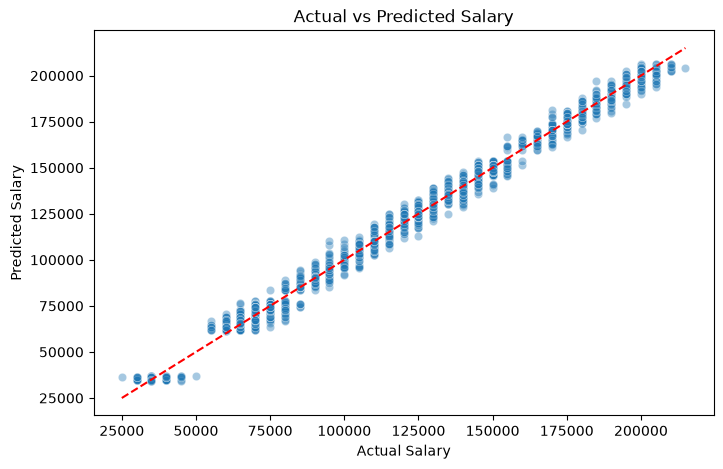

In [ ]:
# Compare actual and predicted salaries
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.4)

# Add a reference line for perfect predictions
# Points closer to this line indicate better model performance
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.show()

### Actual vs Predicted — Findings

- Predicted salaries closely follow actual salaries.
- Most observations are concentrated around the ideal prediction line.
- The model demonstrates strong predictive performance.
- Some prediction errors are visible at the higher salary range.

In [16]:
# Display available options
for col in ["Department", "Job_Title", "Education_Level", "Location"]:
    print(f"{col}: {sorted(df[col].dropna().unique())}")

Department: ['Engineering', 'Finance', 'HR', 'Marketing', 'Product', 'Sales']
Job_Title: ['Analyst', 'Engineer', 'Executive', 'Intern', 'Manager']
Education_Level: ['Bachelor', 'Master', 'PhD']
Location: ['Austin', 'Chicago', 'New York', 'San Francisco', 'Seattle']


In [29]:
# Enter employee information
# Department: Engineering, Sales, Marketing, Finance, HR
# Job Title: Intern, Analyst, Engineer, Manager, Executive
# Education Level: Bachelor, Master, PhD
# Location: Enter a location available in the dataset

age = int(input("Age: "))
experience = float(input("Experience Years: "))
department = input("Department: ").strip()
job_title = input("Job Title: ").strip()
education = input("Education Level: ").strip()
location = input("Location: ").strip()

# Create employee data
new_employee = pd.DataFrame([{
    "Age": age,
    "Experience_Years": experience,
    "Department": department,
    "Job_Title": job_title,
    "Education_Level": education,
    "Location": location
}])

# Predict salary using the trained pipeline
predicted_salary = linear_pipeline.predict(new_employee)

# Display prediction
print(f"\nPredicted Salary: {predicted_salary[0]:,.2f}")

ValueError: invalid literal for int() with base 10: ''